**NOT USED — use `preprocess_artifact_removal_by_sqr_deviation.py` (via `run_preprocess.sh`) instead, the current pipeline.**

**NOTE (legacy/reference, not used anymore):** This notebook is another way to detect eInk artifacts, but does not work as well as using sqr deviation. It detects artifacts by thresholding the raw channel-averaged trace directly against its own mean ± N×std, computed over the *whole* window including the artifact itself. It also still contains an even earlier, abandoned attempt at artifact detection by convolution/moving-average smoothing (dead code, cell just below the imports).

In [2]:
%load_ext autoreload
%autoreload 2

In [3]:
# just for this machine
import os
os.environ["CUDA_VISIBLE_DEVICES"] = "2"

In [4]:
from pathlib import Path

In [5]:
import numpy as np
import matplotlib.pyplot as plt
#import torch
import spikeinterface.full as si
import scipy.signal
from tqdm.auto import tqdm, trange

In [6]:
base_folder = "/u/gongt/GLC6962_g_g0"
spikeglx_folder = os.path.join(base_folder, 'GLC6962_g_g0_imec0')

rec_dir = spikeglx_folder 
#exp_dir = spikeglx_folder / 'kilosort4_cw' / 'kilosort4' / ' '#data_dir / "cuttlefish" / "GLC6962_g_res"

In [7]:
si.set_global_job_kwargs(n_jobs=4)

In [8]:
for meta_filename in Path(spikeglx_folder).glob("*ap.meta"):
    print(meta_filename)

word = 'imSampRate'
with open(meta_filename, 'r') as meta_info:
    # read all lines in a list
    lines = meta_info.readlines()
    for line in lines:
        # check if string present on a current line
        if line.find(word) != -1:
            index = lines.index(line)

line = lines[index]
fs = line[11:]
fs = float(fs)
print(fs)

/u/gongt/GLC6962_g_g0/GLC6962_g_g0_imec0/GLC6962_g_g0_t0.imec0.ap.meta
30000.283520599252


## Preprocessing

In [9]:
rec = si.read_spikeglx(spikeglx_folder, stream_name='imec0.ap', load_sync_channel=False)#si.read_spikeglx(base_folder)
rec.get_probe().to_dataframe()
rec

SpikeGLXRecordingExtractor: 384 channels - 30000.283521 Hz - 1 segments - 80,418,082 samples 
                            2,680.58s (44.68 minutes) - int16 dtype - 57.52 GiB

In [10]:
# this is setup for visualization
n_seconds = rec.get_duration()
n_mins = n_seconds / 60
chlen = 512
t_start = rec.get_start_time()
min_start = int(np.ceil(t_start / 60))

Created folder /u/gongt/GLC6962_g_g0/raw_neural_data for saving images
1577571


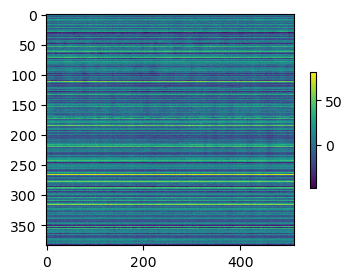

10577656


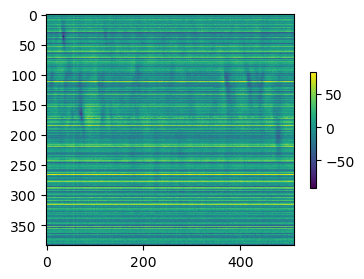

19577741


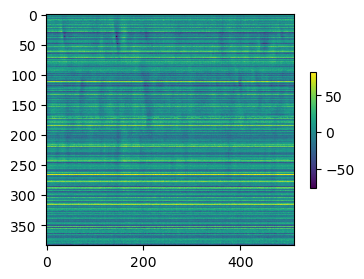

28577826


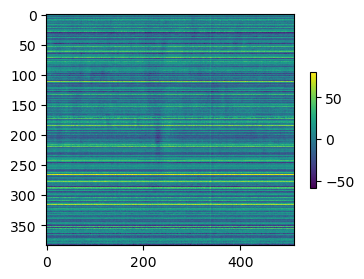

37577911


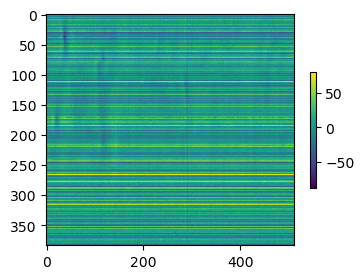

46577996


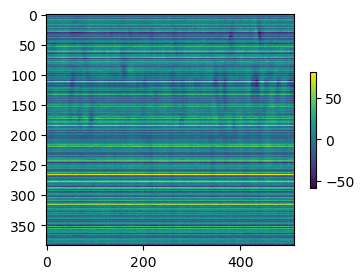

55578081


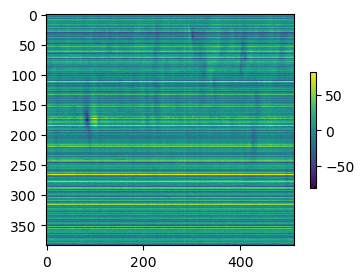

64578166


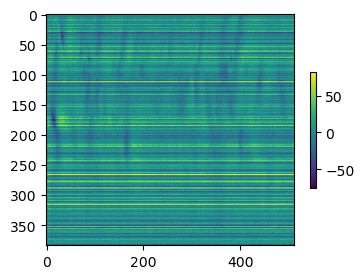

73578251


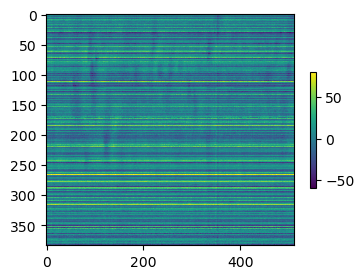

all plots successfully saved


In [12]:
save_folder = os.path.join(base_folder, "raw_neural_data")

if not os.path.exists(save_folder) or len(os.listdir(save_folder)) == 0:
    os.makedirs(save_folder, exist_ok=True)
    print(f"Created folder {save_folder} for saving images")
    imkw = dict(aspect='auto', interpolation='none')
    for min_start in range(min_start, min_start + int(n_mins), 5):
        sample_start = rec.time_to_sample_index(min_start * 60)
        print(sample_start)
        chunk = rec.get_traces(0, sample_start, sample_start + chlen)

        fig, ax = plt.subplots(figsize=(4, 3))
        im = ax.imshow(chunk.T, **imkw)
        plt.colorbar(im, ax=ax, shrink=0.5)

        filename = os.path.join(save_folder, f"{min_start:04d}min.png")
        plt.savefig(filename, bbox_inches = 'tight')
        plt.show()
        plt.close(fig)
    print("all plots successfully saved")
else: 
    print(f"Folder {save_folder} already exists and is not empty. Skip saving images.")

In [13]:
# preprocess
rec0 = si.read_spikeglx(rec_dir, stream_name='imec0.ap', load_sync_channel=False)  # to avoid stacking the ppx chain accidentally.
rec = si.highpass_filter(rec0, dtype="float32")
bc, labels = si.detect_bad_channels(rec, seed=0)
print(f"{bc=}")

bc=array(['imec0.ap#AP191'], dtype='<U64')


In [14]:
rec = rec.remove_channels(bc)

In [15]:
chunks = si.get_random_data_chunks(rec,  num_chunks_per_segment=100, seed=0)

In [16]:
std = chunks.std(0)

In [18]:
peaks, _ = scipy.signal.find_peaks(std, threshold=0.75)
plt.plot(std)
plt.plot(peaks, std[peaks], "x")
plt.xlabel('channel')
plt.ylabel('standard deviation')

save_path = os.path.join(base_folder, "raw_channel_std.png")
if not os.path.exists(save_path):
    plt.savefig(save_path, bbox_inches = 'tight')
    print(f"Saved channel std plot to {save_path}")
else: 
    print(f"Channel std plot {save_path} already exists. Skip saving.")

plt.close()

Saved channel std plot to /u/gongt/GLC6962_g_g0/raw_channel_std.png


In [19]:
rec = rec.remove_channels(rec.channel_ids[peaks])
rec = si.common_reference(rec)

In [20]:

# list_triggers=np.asarray([200.74, 567.52, 570.9, 638.4, 635.23, 683.01, 1184.5, 1184.85, 1470.75, 1476.7, 1482.04, 1485.54, 1508.13, 1869.19, 2167.46, 2435.75, 2639.78])
# list_triggers_samp = list_triggers*fs
# rec_clean = si.remove_artifacts(recording=rec, list_triggers=list_triggers_samp, mode='zeros',ms_before=100,ms_after = 700)


In [20]:
### Extract TTLs ### 
raw_rec = si.read_spikeglx(base_folder, stream_name='nidq', load_sync_channel=False)
raw_rec

SpikeGLXRecordingExtractor: 9 channels - 30002.750562 Hz - 1 segments - 80,424,705 samples 
                            2,680.58s (44.68 minutes) - int16 dtype - 1.35 GiB

In [21]:
ttlName = ['sync','stim','side','overview','hi-res']
input_name = input("Enter a name: ")
chanInterest = ttlName.index(input_name)
chanInterest

3

In [22]:
ttl_sig = raw_rec.get_traces()[:,chanInterest]
norm_sig = (ttl_sig - np.min(ttl_sig)) / (np.max(ttl_sig) - np.min(ttl_sig))
#median_signal = np.median(ttl_sig[ttl_sig > 0])
threshold = 0.5
thresh_signal = (norm_sig >= threshold).astype(int)
diff_sig = np.diff(thresh_signal)

indOn = np.where(diff_sig > 0.6)[0]
indOff = np.where(diff_sig < -0.6)[0]

ttl_on = indOn/fs
ttl_off = indOff/fs

len(ttl_on)

106548

In [23]:
filename = f"ttl_{input_name}_on2.txt"
save_filename = os.path.join(base_folder, filename)
with open(save_filename, "w") as f:
    f.write(",".join(map(str, ttl_on)))

In [24]:
### FIND EINK ARTIFACTS ### 
############## BY CONVOLUTION ###############
def moving_average(signal, window_size):
    kernel = np.ones(window_size) / window_size
    return np.convolve(signal, kernel, mode='same')

rec1 = si.read_spikeglx(base_folder, stream_name='imec0.ap', load_sync_channel=False)

print("getting traces...")
chunk_size = 300000
n_frames = rec1.get_num_frames()
n_chunks = int(np.ceil(n_frames / chunk_size))
accum_sig = []
for i in tqdm(range(n_chunks), desc="Processing chunks"):
    start_frame = i * chunk_size
    end_frame = min((i + 1) * chunk_size, n_frames)
    traces = rec1.get_traces(start_frame=start_frame, end_frame=end_frame)
    # compute mean across channels immediately
    chunk_mean = np.mean(traces, axis=1)
    accum_sig.append(chunk_mean)
mean_sig = np.concatenate(accum_sig)
print(mean_sig.shape)
print("traces retrieved")
meanSub_sig = np.abs(mean_sig) - np.mean(mean_sig)

print("Computing convolution...")
filt_sig = moving_average(meanSub_sig,500)
norm_sig = (filt_sig - np.min(filt_sig)) / (np.max(filt_sig) - np.min(filt_sig))

print("detecting time points")
buffer_window = [500,3000]
threshold = 0.057
thresh_signal = (norm_sig >= threshold).astype(int)
diff_sig = np.diff(thresh_signal)

indOn = np.where(diff_sig > 0.6)[0]
indOff = np.where(diff_sig < -0.6)[0]

if len(indOn) == len(indOff):
    print("Arrays match in length")
else:
    print("Arrays do not match in length")

print(len(indOn))

eInkOn = (indOn - buffer_window[0])/fs
eInkOff = (indOn + buffer_window[1])/fs
print(eInkOn,eInkOff)

getting traces...


Processing chunks:   0%|          | 0/269 [00:00<?, ?it/s]

(80418082,)
traces retrieved
Computing convolution...


KeyboardInterrupt: 

In [ ]:
### FIND EINK ARTIFACTS ###
'''
################ BY MEAN AND STD ###################
rec1 = si.read_spikeglx(base_folder, stream_name='imec0.ap', load_sync_channel=False)

save_folder = Path(os.path.join(base_folder, "artifact_plots", "detection"))
save_folder.mkdir(parents=True, exist_ok=True)

window_size_sec = 60
threshold_std = 1.5
percent_outliers_threshold = 11
threshold_std_extreme = 10
overlap_sec = 1 #when scanning the entire trace, the next chunk has 1s overlap with the previous chunk ==> aoivd an artifact being split into 2 chunks 
total_samples = rec1.get_num_samples(segment_index=0)

window_size = int(window_size_sec * fs)-1
overlap_size = int(overlap_sec * fs)
step_size = window_size - overlap_size

print(f"Total samples: {total_samples}, analyzing in {window_size_sec}s windows")

close_artifact_segments = []  # store sample ranges where space_to_prev <400 for 5 consecutive times
extreme_outliers = []

for start_sample in tqdm(range(0, total_samples, step_size), desc="Scanning dataset by minute"):
    end_sample = min(start_sample + window_size, total_samples)
    trace = rec1.get_traces(0, start_sample, end_sample)
    trace_mean = np.mean(trace, axis=1)
    mean_val = np.mean(trace_mean)
    std_val = np.std(trace_mean)
    upper_threshold = mean_val + threshold_std * std_val
    lower_threshold = mean_val - threshold_std * std_val
    upper_threshold_extreme = mean_val + threshold_std_extreme * std_val
    lower_threshold_extreme = mean_val - threshold_std_extreme * std_val

    # screen for close arttifact clusters 
    outlier_indices = np.where((trace_mean > upper_threshold) | (trace_mean < lower_threshold))[0]
    percent_outliers = (len(outlier_indices) / len(trace_mean)) * 100
    print(f"Chunk {start_sample}–{end_sample}: {percent_outliers:.2f}% of samples exceed threshold")
    if percent_outliers < percent_outliers_threshold: # this filters out chunks where std is small with no huge outliers ==> a lot of samples are above threshold 
        if len(outlier_indices) > 0:
            diffs = np.diff(outlier_indices)
            consecutive_groups = np.split(outlier_indices, np.where(diffs != 1)[0] + 1) #consecutive outliers 
            group_bounds = []
            prev_end = None
            for group in consecutive_groups:
                if len(group) >= 10: # >10 consecutive outliers 
                    group_start = start_sample + group[0]
                    group_end = start_sample + group[-1]
                    if prev_end is not None:
                        space_to_prev = group_start - prev_end #space to previous outlier clusters 
                    else:
                        space_to_prev = None  # still counts as <400
                    group_bounds.append((group_start, group_end, space_to_prev))
                    prev_end = group_end
    
            # compute consecutive small gaps (<400 OR None)
            consec_count = 0
            for i in range(len(group_bounds)):
                gap = group_bounds[i][2]
                if gap is None or gap < 400: #for eInk artifacts, gap is usually ~368 ==> closely spaced outlier clusters 
                    consec_count += 1
                    if consec_count >= 5: # > 5 closely spaced outlier clusters, neuronal spikes should not be able to fire so consecutively 
                        # mark start of the first group in this run and end of current
                        start_run = group_bounds[i - 4][0]
                        end_run = group_bounds[i][1]
                        close_artifact_segments.append((start_run, end_run))
                        #print(start_run, end_run) 
                        consec_count = 0  # reset after noting
                else:
                    consec_count = 0
    # screen for extreme outliers 
    outlier_indices_extreme = np.where((trace_mean > upper_threshold_extreme) | (trace_mean < lower_threshold_extreme))[0] + start_sample
    print("outlier_indices_extreme", outlier_indices_extreme) 
    extreme_outliers.append(outlier_indices_extreme)
    
    # plot chunk if consecutive outlier clusters are detected 
    segments_in_window = [(s, e) for (s, e) in close_artifact_segments if not (e < start_sample or s > end_sample)]
    if segments_in_window:
        print(segments_in_window)
        # plot results to check 
    x = np.arange(start_sample, end_sample)
    fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(20, 3), sharey=True)
    ax.plot(x, trace_mean)

    # highlight all detected outlier groups in red
    for (seg_start, seg_end) in close_artifact_segments:
        seg_mask = (x >= seg_start) & (x <= seg_end)
        ax.plot(x[seg_mask], trace_mean[seg_mask], color='red', linewidth=2)

    extreme_indices_rel = outlier_indices_extreme - start_sample
    # plot dots for extreme outliers outside the red segments
    if extreme_indices_rel.size > 0:
        y_extreme = np.full(len(extreme_indices_rel), upper_threshold_extreme)
        ax.plot(x[extreme_indices_rel], y_extreme, 'ro', markersize=4, label='Extreme Outliers')

    ax.axhline(upper_threshold, color='red', linestyle='--', linewidth=1)
    ax.axhline(lower_threshold, color='red', linestyle='--', linewidth=1)
    ax.axhline(upper_threshold_extreme, color='red', linestyle='--', linewidth=1)
    ax.axhline(lower_threshold_extreme, color='red', linestyle='--', linewidth=1)
    
    ax.set_title("Original Trace with Dense Artifact Sequences")

    save_path = save_folder / f"artifact_{start_sample}_{end_sample}.png"
    plt.savefig(save_path)
    plt.close(fig)
'''

Total samples: 1082222502, analyzing in 60s windows


Scanning dataset by minute:   0%|          | 0/612 [00:00<?, ?it/s]

Chunk 0–1799999: 12.73% of samples exceed threshold
outlier_indices_extreme []
Chunk 1769999–3569998: 12.73% of samples exceed threshold
outlier_indices_extreme []
Chunk 3539998–5339997: 12.73% of samples exceed threshold
outlier_indices_extreme []
Chunk 5309997–7109996: 12.71% of samples exceed threshold
outlier_indices_extreme []
Chunk 7079996–8879995: 12.75% of samples exceed threshold
outlier_indices_extreme [7318757 7318758 7318759 7318760 7318761 7318762 7341762 7341763 7341764
 7341765 7341766]
Chunk 8849995–10649994: 12.82% of samples exceed threshold
outlier_indices_extreme []
Chunk 10619994–12419993: 12.74% of samples exceed threshold
outlier_indices_extreme []
Chunk 12389993–14189992: 12.75% of samples exceed threshold
outlier_indices_extreme []
Chunk 14159992–15959991: 12.74% of samples exceed threshold
outlier_indices_extreme []
Chunk 15929991–17729990: 12.69% of samples exceed threshold
outlier_indices_extreme [16829268 16829667 16830067 16830068 16830467 16830867 1683126

In [ ]:
# print all detected artifact segments
'''
eInkOn = []
eInkOff = []
for seg in close_artifact_segments:
    eInkOn.append(seg[0]/fs)
    eInkOff.append(seg[1]/fs)
'''

In [ ]:
'''
extreme_outliers = np.concatenate(extreme_outliers).tolist()
print(extreme_outliers)
'''

[6022644, 6022645, 6022646, 6022647, 6022648, 6022649, 6022650, 6022651, 6022652, 6022653, 6022654, 6022655, 6022656, 6022657, 6022658, 6022659, 6022660, 6022661, 6022662, 6022663, 6022664, 6022665, 6022666, 6022667, 6022668, 6022669, 6022675, 6022676, 6022677, 6022678, 6022679, 6022680, 6022681, 6022682, 6022683, 6022686, 6022687, 6022688, 6022689, 6022690, 6022691, 6022692, 6022693, 6022694, 6022695, 6022696, 6022697, 6022703, 6022704, 6022714, 6022715, 6022716, 6022717, 6022719, 6022720, 6022730, 6022731, 6022732, 6022733, 6022734, 6022735, 6022736, 6022743, 6022744, 6022770, 6022775, 6022793, 6022803, 6022804, 6022805, 6022806, 6022807, 6022808, 6022831, 6022838, 6022840, 6022841, 6022842, 6022843, 6022844, 6022853, 6022882, 6022883, 6022884, 6022891, 6022892, 6022893, 6022894, 6022895, 6022896, 6022912, 6022913, 6022914, 6022915, 6022916, 6022924, 6022929, 6022931, 6022932, 6022933, 6022934, 6022948, 6022951, 6022952, 6022953, 6022954, 6022960, 6022968, 6022969, 6022970, 6022971, 

In [18]:
print("eInkOn:", eInkOn)
print("eInkOff:", eInkOff)

eInkOn: [ 200.73076667  200.84473333  549.54186667  549.6562      567.49716667
  567.6114      567.75246667  567.7656      567.77983333  567.79253333
  567.85453333  567.8666      567.88        567.89356667  570.9546
  570.96816667  570.98163333  570.99456667  571.069       571.0827
  571.09573333  635.36936667  638.42986667  638.4431      638.4564
  638.47        638.54436667  638.5575      638.5708      683.00523333
  683.11953333 1184.83676667 1184.95093333 1470.77426667 1470.78846667
 1470.80136667 1470.81423333 1470.89053333 1470.8907     1476.7217
 1476.74896667 1476.7618     1476.86333333 1482.09693333 1482.1119
 1482.13756667 1482.13776667 1482.211      1482.23926667 1482.23933333
 1485.54133333 1485.55533333 1485.55606667 1485.65553333 1508.145
 1508.2593     1869.19383333 1869.30803333 2167.45623333 2167.57053333
 2435.75893333 2435.87306667 2639.784      2639.89846667]
eInkOff: [ 200.84743333  200.9614      549.65853333  549.77286667  567.61383333
  567.72806667  567.8691333

In [ ]:
'''
def save_array(arr, label):
    filename = f"{label}_{input_name}.txt"
    save_path = os.path.join(base_folder, filename)
    with open(save_path, "w") as f:
        f.write(",".join(map(str, arr)))

save_array(eInkOn, "eInk_on")
save_array(eInkOff, "eInk_off")
save_array(extreme_outliers, "extreme_outliers")
'''

In [20]:
'''
#### if triggers already known ## 
eInkOn = np.loadtxt(f"{base_folder}/eInk_on_overview.txt", delimiter=',')
eInkOff = np.loadtxt(f"{base_folder}/eInk_off_overview.txt", delimiter=',')
extreme_outliers = np.loadtxt(f"{base_folder}/extreme_outliers_overview.txt", delimiter=',')
#####
'''

#print(eInkOff - eInkOn)
eInkOn = np.array(eInkOn)
eInkOff = np.array(eInkOff)
list_triggers = eInkOn
list_triggers_samp = list_triggers*fs
print(len(list_triggers))

ms_before = 150
ms_after = np.max(eInkOff - eInkOn)*1000+150
print("ms_after:", ms_after)

ms_outliers = 50
rec_clean = si.remove_artifacts(recording=rec, list_triggers=list_triggers_samp, mode='zeros',ms_before=ms_before,ms_after = ms_after)
#rec_clean = si.remove_artifacts(recording=rec_clean, list_triggers=extreme_outliers, mode='zeros',ms_before=ms_outliers,ms_after = ms_outliers)

print(list_triggers)

64
ms_after: 266.66666666678793
[ 200.73076667  200.84473333  549.54186667  549.6562      567.49716667
  567.6114      567.75246667  567.7656      567.77983333  567.79253333
  567.85453333  567.8666      567.88        567.89356667  570.9546
  570.96816667  570.98163333  570.99456667  571.069       571.0827
  571.09573333  635.36936667  638.42986667  638.4431      638.4564
  638.47        638.54436667  638.5575      638.5708      683.00523333
  683.11953333 1184.83676667 1184.95093333 1470.77426667 1470.78846667
 1470.80136667 1470.81423333 1470.89053333 1470.8907     1476.7217
 1476.74896667 1476.7618     1476.86333333 1482.09693333 1482.1119
 1482.13756667 1482.13776667 1482.211      1482.23926667 1482.23933333
 1485.54133333 1485.55533333 1485.55606667 1485.65553333 1508.145
 1508.2593     1869.19383333 1869.30803333 2167.45623333 2167.57053333
 2435.75893333 2435.87306667 2639.784      2639.89846667]


In [21]:
####### SWEEP ACROSS THE WHOLE DATASET - CHECK IF ALL ARTIFACTS ARE REMOVED ###########
rec1 = si.read_spikeglx(base_folder, stream_name='imec0.ap', load_sync_channel=False)

save_folder = Path(os.path.join(base_folder, "artifact_plots_original", "confirmation"))
save_folder.mkdir(parents=True, exist_ok=True)

window_size_sec = 20
threshold_std = 1.5
percent_outliers_threshold = 11
overlap_sec = 1 #when scanning the entire trace, the next chunk has 1s overlap with the previous chunk ==> aoivd an artifact being split into 2 chunks 
total_samples = rec1.get_num_samples(segment_index=0)

window_size = int(window_size_sec * fs)-1
overlap_size = int(overlap_sec * fs)
step_size = window_size - overlap_size

print(f"Total samples: {total_samples}, analyzing in {window_size_sec}s windows")

close_artifact_segments = []  # store sample ranges where space_to_prev <400 for 5 consecutive times

rec_clean_astype = rec_clean.astype('float16')

remaining_outliers = []
for start_sample in tqdm(range(0, total_samples, step_size), desc="Scanning dataset by minute"):
    end_sample = min(start_sample + window_size, total_samples)
    trace = rec1.get_traces(0, start_sample, end_sample)
    trace_mean = np.mean(trace, axis=1)
    mean_val = np.mean(trace_mean)
    std_val = np.std(trace_mean)
    upper_threshold = mean_val + threshold_std * std_val
    lower_threshold = mean_val - threshold_std * std_val
    outlier_indices = np.where((trace_mean > upper_threshold) | (trace_mean < lower_threshold))[0]
    percent_outliers = (len(outlier_indices) / len(trace_mean)) * 100
    print(f"Chunk {start_sample}–{end_sample}: {percent_outliers:.2f}% of samples exceed threshold")

    if percent_outliers < percent_outliers_threshold: # this filters out chunks where std is small with no huge outliers ==> a lot of samples are above threshold  
        clean_trace = rec_clean_astype.get_traces(0, start_sample, end_sample)
        clean_trace_mean = np.mean(clean_trace, axis=1)
        clean_mean_val = np.mean(clean_trace_mean)
        clean_std_val = np.std(clean_trace_mean)
        clean_upper_threshold = clean_mean_val + threshold_std * clean_std_val
        clean_lower_threshold = clean_mean_val - threshold_std * clean_std_val
        clean_outlier_indices = np.where((clean_trace_mean > clean_upper_threshold) | (clean_trace_mean < clean_lower_threshold))[0]
        clean_percent_outliers = (len(clean_outlier_indices) / len(clean_trace_mean)) * 100
        
        if clean_percent_outliers < percent_outliers_threshold and len(clean_outlier_indices) > 0: 
            remaining_outliers.append(clean_outlier_indices+start_sample) 
        print(f"Chunk {start_sample}–{end_sample}: {clean_percent_outliers:.2f}% of samples exceed threshold")
        
        x = np.arange(start_sample, end_sample) / fs
        fig, (ax, ay) = plt.subplots(nrows=2, ncols=1, figsize=(20, 6), sharey=True)
        ax.plot(x, trace_mean[:], color = 'black')
        ax.set_title('Original Trace')
        ay.plot(x, clean_trace_mean[:], color = 'black')
        ay.set_title('Clean Trace')
        zero_mask = (clean_trace_mean == 0)
        if np.any(zero_mask):
            ay.scatter(x[zero_mask], clean_trace_mean[zero_mask], color='red', s=10, label='Zeroed samples')
            
        save_path = save_folder / f"artifact_{start_sample}_{end_sample}.png"
        plt.savefig(save_path)
        plt.close(fig)

Total samples: 86545524, analyzing in 20s windows


Scanning dataset by minute:   0%|          | 0/152 [00:00<?, ?it/s]

Chunk 0–599999: 12.82% of samples exceed threshold
Chunk 569999–1169998: 12.74% of samples exceed threshold
Chunk 1139998–1739997: 12.69% of samples exceed threshold
Chunk 1709997–2309996: 12.70% of samples exceed threshold
Chunk 2279996–2879995: 12.71% of samples exceed threshold
Chunk 2849995–3449994: 12.79% of samples exceed threshold
Chunk 3419994–4019993: 12.85% of samples exceed threshold
Chunk 3989993–4589992: 12.72% of samples exceed threshold
Chunk 4559992–5159991: 12.72% of samples exceed threshold
Chunk 5129991–5729990: 12.68% of samples exceed threshold
Chunk 5699990–6299989: 0.61% of samples exceed threshold
Chunk 5699990–6299989: 11.97% of samples exceed threshold
Chunk 6269989–6869988: 12.69% of samples exceed threshold
Chunk 6839988–7439987: 12.68% of samples exceed threshold
Chunk 7409987–8009986: 12.69% of samples exceed threshold
Chunk 7979986–8579985: 12.67% of samples exceed threshold
Chunk 8549985–9149984: 12.69% of samples exceed threshold
Chunk 9119984–9719983: 

/u/gongt/.local/lib/python3.10/site-packages/numpy/core/_methods.py:187: RuntimeWarning: overflow encountered in reduce
  ret = umr_sum(x, axis, dtype, out, keepdims=keepdims, where=where)


Chunk 15959972–16559971: 0.00% of samples exceed threshold
Chunk 16529971–17129970: 0.50% of samples exceed threshold
Chunk 16529971–17129970: 0.00% of samples exceed threshold
Chunk 17099970–17699969: 6.21% of samples exceed threshold
Chunk 17099970–17699969: 0.00% of samples exceed threshold
Chunk 17669969–18269968: 12.68% of samples exceed threshold
Chunk 18239968–18839967: 12.67% of samples exceed threshold
Chunk 18809967–19409966: 4.27% of samples exceed threshold
Chunk 18809967–19409966: 0.00% of samples exceed threshold
Chunk 19379966–19979965: 12.71% of samples exceed threshold
Chunk 19949965–20549964: 0.66% of samples exceed threshold
Chunk 19949965–20549964: 0.00% of samples exceed threshold
Chunk 20519964–21119963: 12.76% of samples exceed threshold
Chunk 21089963–21689962: 12.65% of samples exceed threshold
Chunk 21659962–22259961: 12.74% of samples exceed threshold
Chunk 22229961–22829960: 12.70% of samples exceed threshold
Chunk 22799960–23399959: 12.68% of samples exceed

In [22]:
print(remaining_outliers)
'''
if len(remaining_outliers) > 0: 
    raise Exception("There may be remaining outliers in the cleaned trace. please check manually!")
'''

[]


'\nif len(remaining_outliers) > 0: \n    raise Exception("There may be remaining outliers in the cleaned trace. please check manually!")\n'

In [ ]:
###################################################

In [ ]:
rec = rec_clean

In [ ]:
chunks = si.get_random_data_chunks(rec,  num_chunks_per_segment=100, seed=0)
chunks.shape

(1500000, 369)

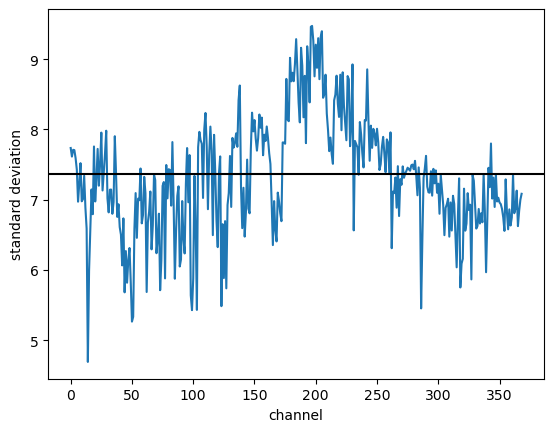

In [ ]:
std = chunks.std(0)
gstd = chunks.std()
plt.plot(std)
plt.axhline(gstd, color='k')
plt.xlabel('channel')
plt.ylabel('standard deviation')

save_path = save_folder / f"processed_channel_std.png"
if not os.path.exists(save_path):
    plt.savefig(save_path, bbox_inches = 'tight')
    print(f"Saved channel std plot to {save_path}")
else: 
    print(f"Channel std plot {save_path} already exists. Skip saving.")
plt.close(fig)

In [ ]:
rec = si.scale(rec, gain=1.0 / gstd, dtype='float16')

In [ ]:
n_seconds = rec.get_duration()
n_mins = n_seconds / 60
chlen = 512
t_start = rec.get_start_time()
min_start = int(np.ceil(t_start / 60))

1670280


/tmp/ipykernel_49246/137642399.py:12: DeprecationWarning: `return_scaled` is deprecated and will be removed in version 0.105.0. Use `return_in_uV` instead.
  chunk0 = rechp.get_traces(0, sample_start, sample_end, return_scaled=True)


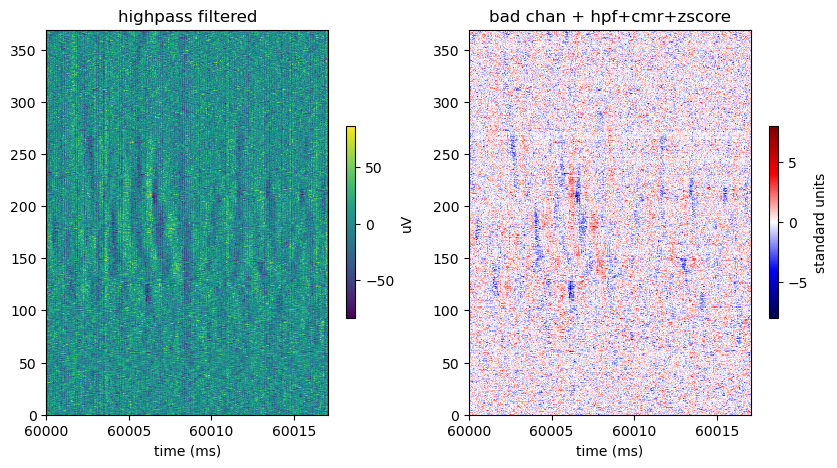

10670280


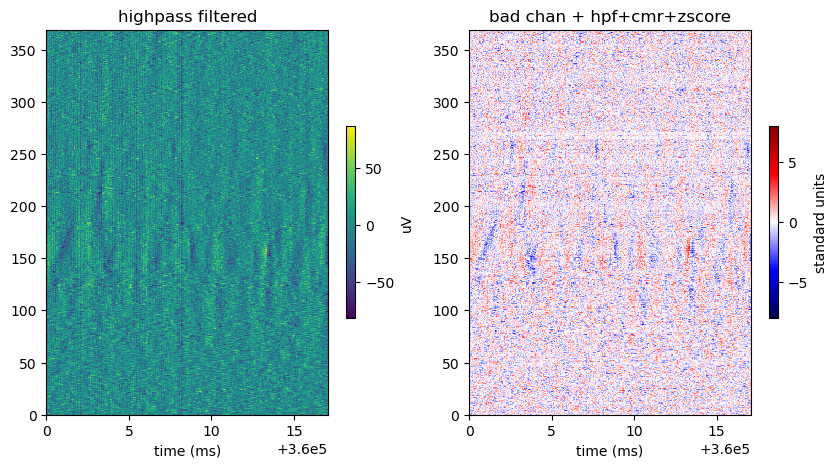

19670280


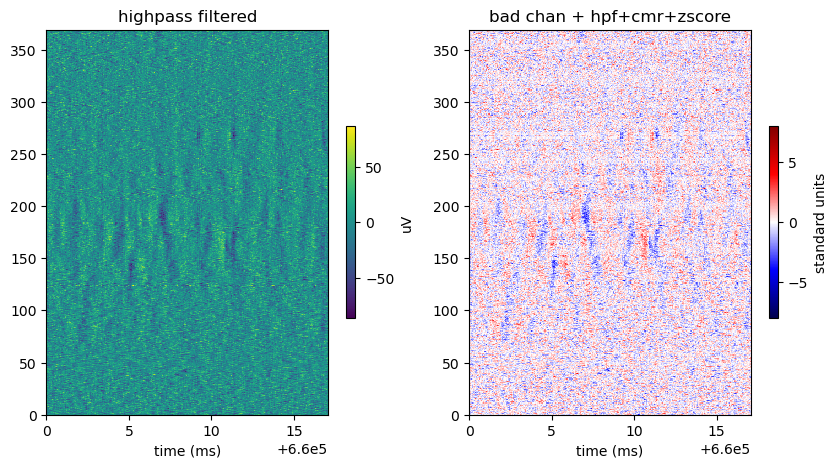

28670280


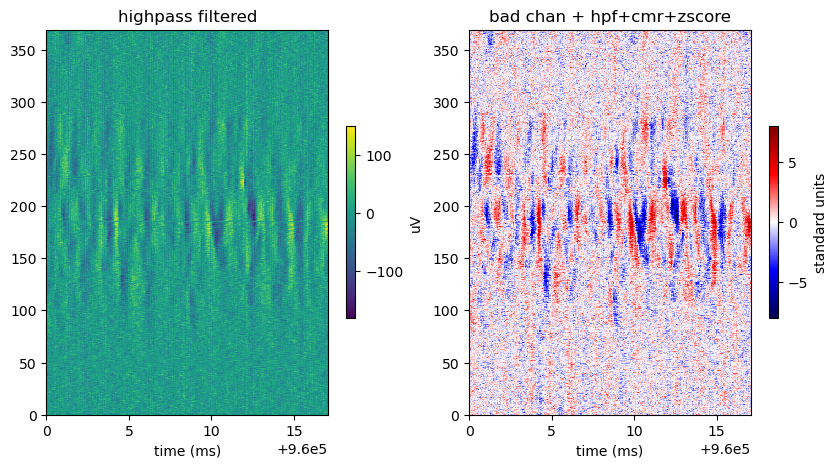

37670280


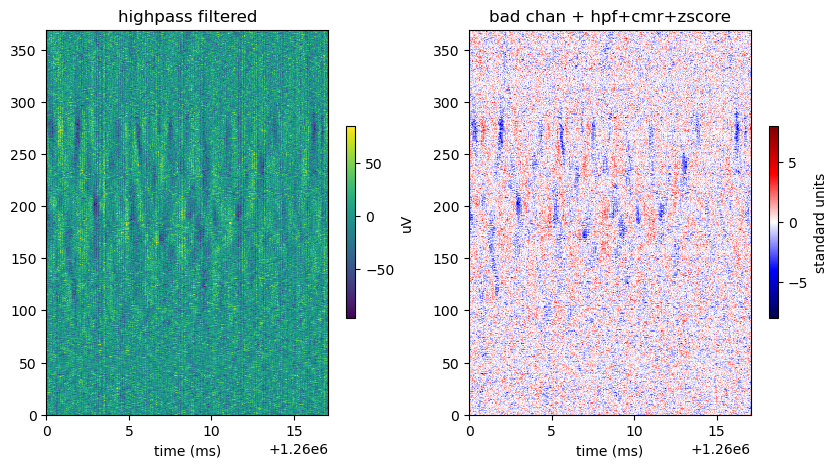

46670280


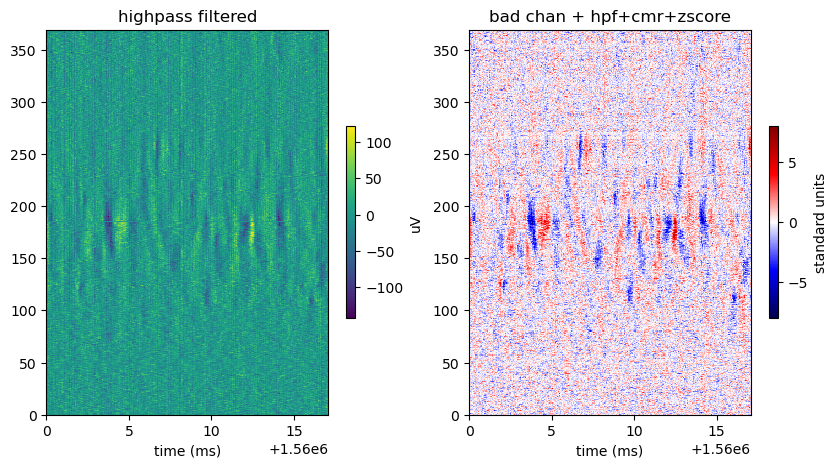

55670280


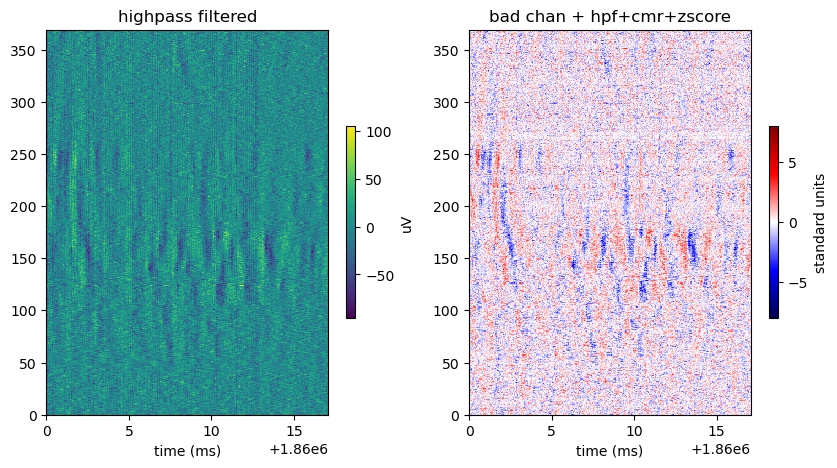

64670280


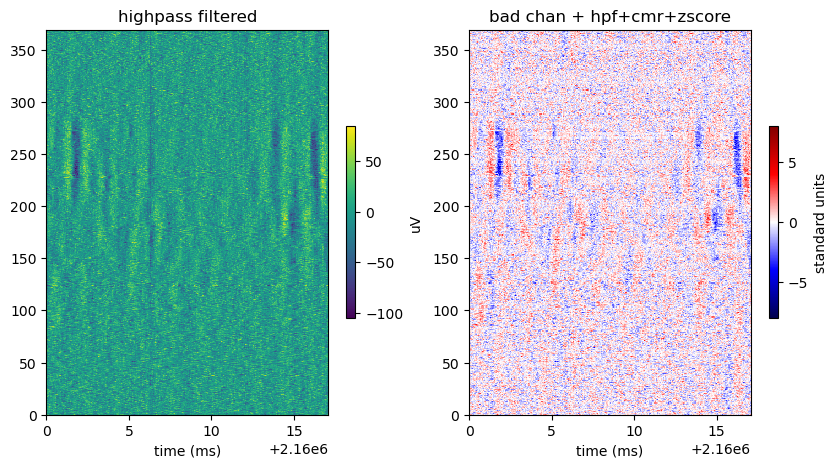

73670280


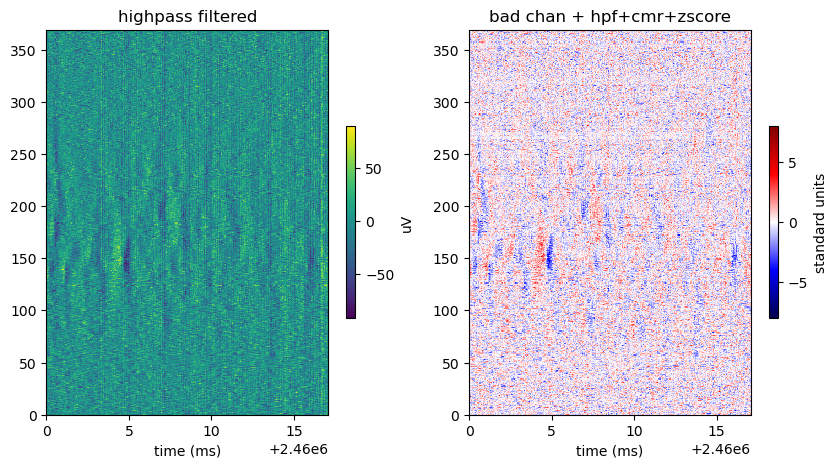

82670280


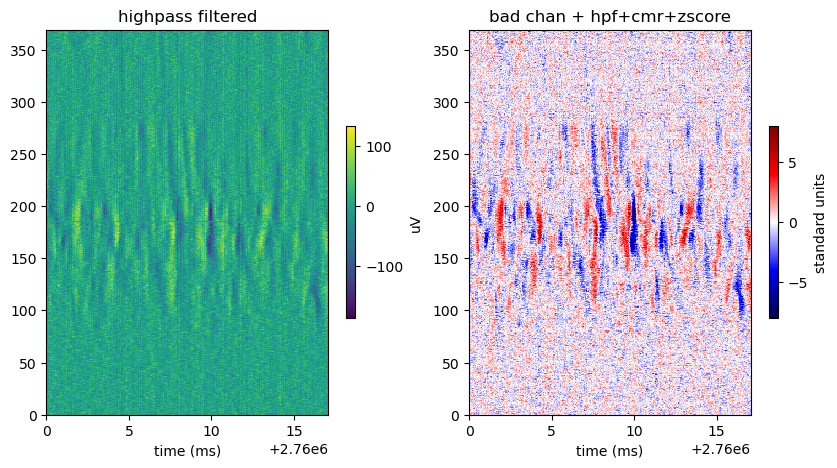

In [ ]:
save_folder = os.path.join(base_folder, "processed_neural_data")

if not os.path.exists(save_folder) or len(os.listdir(save_folder)) == 0:
    print(f"Created folder {save_folder} for saving images")
    imkw0 = dict(aspect='auto', interpolation='none', cmap='viridis')
    imkw = dict(aspect='auto', interpolation='none', cmap='seismic', vmin=-8, vmax=8)
    rechp = si.highpass_filter(si.read_spikeglx(rec_dir, stream_name='imec0.ap', load_sync_channel=False))

    for min_start in range(min_start, min_start + int(n_mins), 5):
        sample_start = rec.time_to_sample_index(min_start * 60)
        sample_end = sample_start + chlen
        t_start = rec.sample_index_to_time(sample_start) * 1000
        t_end = rec.sample_index_to_time(sample_end) * 1000
        print(sample_start)

        chunk0 = rechp.get_traces(0, sample_start, sample_end, return_scaled=True)
        chunk = rec.get_traces(0, sample_start, sample_end)

        fig, (ax, ay) = plt.subplots(ncols=2, figsize=(10, 5))

        im = ax.imshow(chunk0.T, extent=(t_start, t_end, 0, rec.get_num_channels()), **imkw0)
        plt.colorbar(im, ax=ax, shrink=0.5, label='uV')

        im = ay.imshow(chunk.T, extent=(t_start, t_end, 0, rec.get_num_channels()), **imkw)
        plt.colorbar(im, ax=ay, shrink=0.5, label='standard units')

        ax.set_title('highpass filtered')
        ay.set_title('bad chan + hpf+cmr+zscore')
        ax.set_xlabel("time (ms)")
        ay.set_xlabel("time (ms)")

        save_path = os.path.join(save_folder, f"segment_{min_start}min.png")
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
        plt.close(fig)
        
    print("all plots successfully saved")
else: 
    print(f"Folder {save_folder} already exists and is not empty. Skip saving images.")

In [ ]:
rec = rec.astype('float16')

In [ ]:
rec

astype (AstypeRecording): 369 channels - 30.0kHz - 1 segments - 86,545,524 samples 
        2,884.85s (48.08 minutes) - float16 dtype - 59.48 GiB

In [ ]:
rec.save_to_folder(os.path.join(base_folder, "preprocessed"), overwrite=True, n_jobs=8)

Use cache_folder=/u/gongt/GLC7189_c_g0/preprocessed
write_binary_recording 
engine=process - n_jobs=8 - samples_per_chunk=30,000 - chunk_memory=21.11 MiB - total_memory=168.91 MiB - chunk_duration=1.00s


write_binary_recording (workers: 8 processes):   0%|          | 0/2885 [00:00<?, ?it/s]

BinaryFolderRecording: 369 channels - 30.0kHz - 1 segments - 86,545,524 samples 
                       2,884.85s (48.08 minutes) - float16 dtype - 59.48 GiB